<a href="https://colab.research.google.com/github/bsheese/387/blob/main/22_images/22_2_Autoencoders_and_Diffusion/22_2_2_Diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Images: Part 6
## Diffusion: Denoising, Repeated

---

## What This Notebook Is About

22_2_1 trained a network to remove noise from an image in one step. It worked when the noise was light, but from heavy noise or pure noise it could only produce a blurred, average-looking garment. The image generators that became widely used from 2022 on, such as Stable Diffusion and DALL·E 2, are built on a way around that problem, called **diffusion**. A diffusion model is trained to remove a *small* amount of noise at *every* noise level. To make a new image, it starts from pure noise and removes a little at a time, many times over, so that each step is an easy one.

This notebook doesn't train a diffusion model, which takes days on many GPUs. It uses two pretrained ones and opens up how they work:

1. How noise is added in many small steps, and what a diffusion model is trained to do
2. The generation loop, written out by hand, with the image at each step and the model's running guess of the finished image
3. What the random starting noise and the number of steps change
4. **Text-to-image**: a compressed version of Stable Diffusion that makes a picture from a description, and how it uses an autoencoder like 22_2_1's
5. Where the training images for these models came from, and some of the problems that raises

Sections 1 to 4 run on a GPU or a CPU; on Colab's CPU the longest cell takes 2 to 3 minutes. Section 5's text-to-image cells download a 2.7 GB model and take a minute or two on Colab's GPU (Runtime → Change runtime type → T4 GPU), but **more than 10 minutes on Colab's CPU**. Without a GPU, read their saved outputs instead of running them: the notebook is saved with all of its outputs.

In [1]:
import os
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torchvision import transforms as T

os.environ['HF_HUB_DISABLE_XET'] = '1'      # use the standard download method for Hugging Face models
from diffusers import DDIMScheduler, UNet2DModel

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    # It saves to a temporary name first, so a download that fails partway doesn't leave a broken file behind.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name + '.part')
        os.replace(name + '.part', name)
    return name

def show(x):
    # The models work with pixel values from -1 to 1; matplotlib wants 0 to 1, with the color channels last.
    return ((x.detach().cpu().permute(1, 2, 0) + 1) / 2).clamp(0, 1)

device: cpu


`diffusers` is Hugging Face's library for diffusion models. Like `torchvision.models` in 19_0, it downloads pretrained models by name.

---

## Section 1: Adding Noise in Small Steps

A diffusion model is defined by a **noise schedule**: a fixed recipe for turning a clean image into pure noise over many steps, here 1,000. At step $t$ the noisy image is a mix of the clean image and random noise:

$$\text{noisy image} = a_t \times \text{clean image} + b_t \times \text{noise}$$

where the noise is one fixed image of random numbers from the bell curve (as in 22_2_1), and the two weights $a_t$ and $b_t$ are set by the schedule, with $a_t^2 + b_t^2 = 1$. At step 0, $a_t$ is 1 and the image is clean. As $t$ grows, $a_t$ shrinks toward 0 and $b_t$ grows toward 1, so by the last step almost nothing of the image is left.

The schedule lives in a **scheduler** object. We load the one that belongs to the model we use in Section 3, and apply it to a photo from 19_0, shrunk to 32 × 32 pixels, the size that model works with.

noise steps in the schedule: 1000


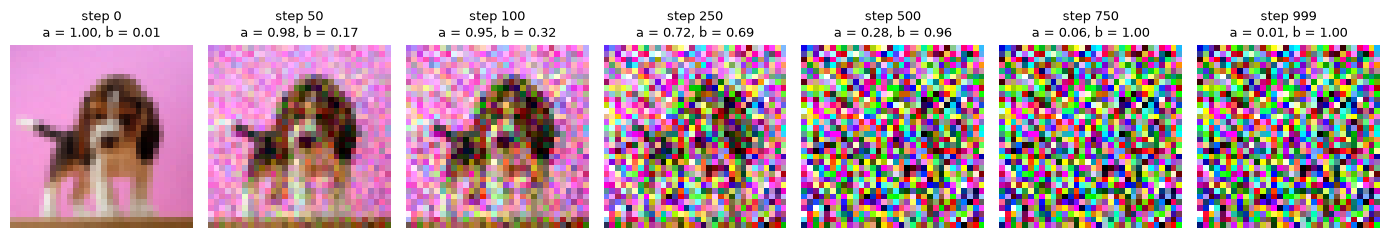

In [2]:
scheduler = DDIMScheduler.from_pretrained('google/ddpm-cifar10-32')
print('noise steps in the schedule:', scheduler.config.num_train_timesteps)

with zipfile.ZipFile(fetch('pets4.zip')) as z:
    photo = Image.open(z.open('pets4/test/beagle/beagle_1.jpg')).convert('RGB')
to_tensor = T.Compose([T.Resize(32), T.CenterCrop(32), T.ToTensor()])
clean = to_tensor(photo) * 2 - 1                  # pixel values from -1 to 1, the range the model uses

torch.manual_seed(0)
noise = torch.randn_like(clean)
steps = [0, 50, 100, 250, 500, 750, 999]

fig, axes = plt.subplots(1, len(steps), figsize=(14, 2.6))
for ax, t in zip(axes, steps):
    noisy = scheduler.add_noise(clean, noise, torch.tensor([t]))
    a = scheduler.alphas_cumprod[t].sqrt()
    ax.imshow(show(noisy))
    ax.set_title(f'step {t}\na = {a:.2f}, b = {(1 - a**2).sqrt():.2f}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

At step 50 (a = 0.98) the beagle is clear under a light speckle. At step 100 (a = 0.95, b = 0.32) it is still easy to see, and at step 250, where the two weights are about equal (0.72 and 0.69), only a dark outline is left. From step 500 on (a = 0.28 and lower), the image looks like pure noise to a person, although at step 500 a little more than a quarter of the photo is still mixed in. By step 999, a is 0.01.

Most of the change to what we can see happens early, between steps 0 and 250. The schedule was designed that way. The later steps, where the image already looks like noise, are the ones where a generated image's overall layout gets decided, as Section 3 shows.

### How a diffusion model is trained

Training uses the same idea as 22_2_1, with two changes. For each training image, pick a random step $t$ between 0 and 999, make the noisy image for that step, and ask the network for the **noise** that was added (rather than for the clean image). The loss is the mean squared error between the network's answer and the noise that was really added. The network is also told the step number $t$, so a single network learns to handle every noise level, from barely noisy to pure noise.

Predicting the noise is equivalent to predicting the clean image: if you know the noisy image, the step and the noise, the formula above can be solved for the clean image. Diffusion models are usually trained to predict the noise because it works a little better in practice.

---

## Section 2: One Model, One Step

The model we use is the diffusion model for 32 × 32 color images from the paper that made the method practical (Ho, Jain and Abbeel, *Denoising Diffusion Probabilistic Models*, 2020). It was trained on the 50,000 training images of **CIFAR-10**, a dataset of small photos in ten classes: airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships and trucks. The network is a **U-Net**, a CNN that shrinks the image and then enlarges it again, like 22_2_1's autoencoder, but with extra connections that pass each size of the image directly from the shrinking half to the enlarging half, so fine detail doesn't have to squeeze through the bottleneck.

Before generating anything, here is the trained network doing its one job on our beagle: given the noisy photo and the step number, guess the noise, and from that, the clean image.

weights: 35,746,307


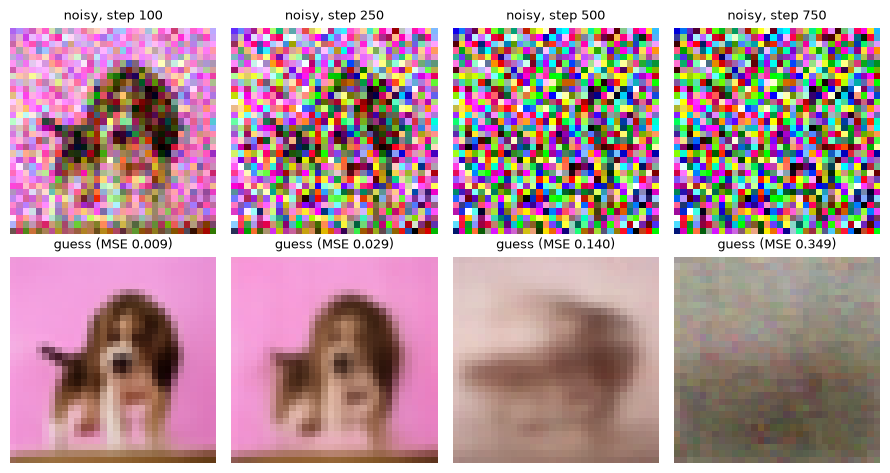

In [3]:
unet = UNet2DModel.from_pretrained('google/ddpm-cifar10-32').to(device).eval()
print(f'weights: {sum(p.numel() for p in unet.parameters()):,}')

fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for c, t in enumerate([100, 250, 500, 750]):
    noisy = scheduler.add_noise(clean, noise, torch.tensor([t]))
    with torch.no_grad():
        noise_guess = unet(noisy[None].to(device), t).sample[0].cpu()     # in: noisy image and step; out: the noise
    a = scheduler.alphas_cumprod[t].sqrt()
    b = (1 - a**2).sqrt()
    clean_guess = (noisy - b * noise_guess) / a                           # the formula above, solved for the clean image
    error = ((clean_guess.clamp(-1, 1) - clean) ** 2).mean().item()        # how far the guess is from the real photo
    axes[0, c].imshow(show(noisy)); axes[0, c].set_title(f'noisy, step {t}', fontsize=9)
    axes[1, c].imshow(show(clean_guess)); axes[1, c].set_title(f'guess (MSE {error:.3f})', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

The bottom row is what 22_2_1's denoiser did, but at four noise levels with one network. At steps 100 and 250 the guess is a clean, slightly blurred beagle on a pink background, with a mean squared error of 0.009 and 0.029 (on the −1 to 1 pixel scale), even though at step 250 the beagle was hard to see in the noisy image. At step 500 the guess is a brown smear with no recognizable dog (0.140), and at step 750 it is a grey-brown blur with nothing of the photo in it (0.349).

That is the same limit 22_2_1 ran into: from heavy noise, a single guess comes out blurred, because the mean squared error rewards a compromise between all the images the noisy one could have come from. A diffusion model doesn't try to make its final image from that one guess. It only uses the guess to take one small step to a slightly less noisy image, and then guesses again.

---

## Section 3: Generating an Image, Step by Step

To make a new image, start from pure noise (as if at step 999) and repeat:

1. Ask the network for the noise in the current image, and from that compute its guess of the clean image.
2. Move to an earlier step: mix that guess with the network's noise estimate, using the weights $a_t$ and $b_t$ of the earlier step. The result is a slightly less noisy image.

The original method went through all 1,000 steps. A later paper (Song, Meng and Ermon, *Denoising Diffusion Implicit Models*, 2020) showed how to take larger jumps, for example 50 steps of 20, with nearly the same results; that is the `DDIMScheduler` here. The scheduler's `step` function does step 2, and it also returns the guess of the clean image, which we keep so we can watch it change.

The loop below is the whole generation algorithm. It makes four images at once.

4 images, 50 steps: 7.8 s
scheduler.timesteps starts [980, 960, 940, 920] and ends [40, 20, 0]


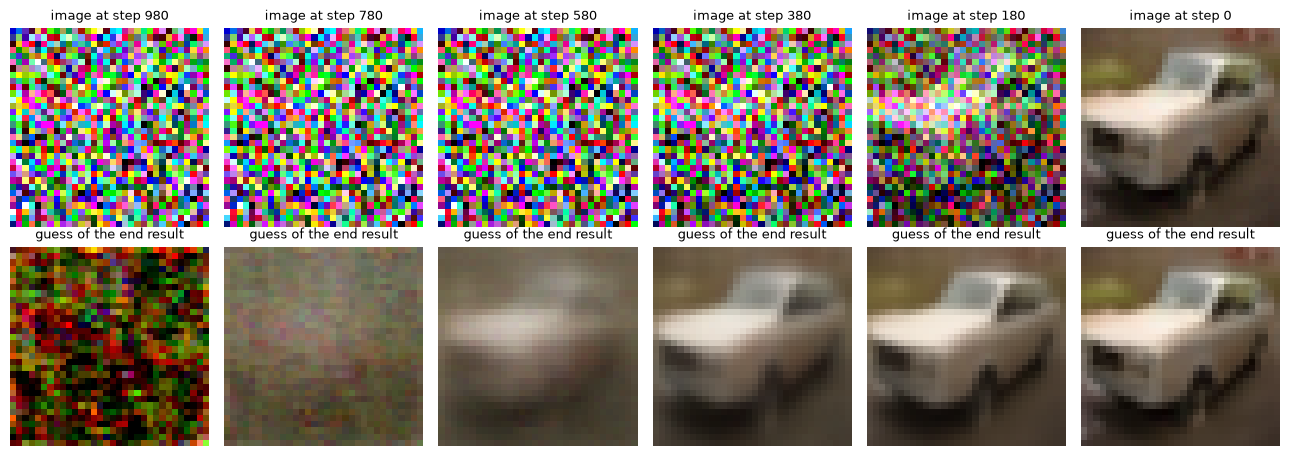

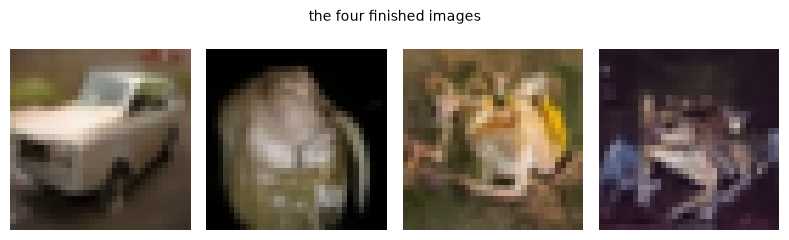

In [4]:
def generate(n_images, n_steps, seed, keep_every=None):
    scheduler.set_timesteps(n_steps)                                # which of the 1,000 steps to visit
    generator = torch.Generator().manual_seed(seed)
    x = torch.randn((n_images, 3, 32, 32), generator=generator).to(device)   # start from pure noise
    images, guesses = [], []
    with torch.no_grad():
        for i, t in enumerate(scheduler.timesteps):
            noise_guess = unet(x, t).sample                         # 1. the network's estimate of the noise
            result = scheduler.step(noise_guess, t, x)              # 2. move to an earlier, less noisy step
            if keep_every and (i % keep_every == 0 or i == n_steps - 1):
                images.append((int(t), x[0].cpu()))
                guesses.append(result.pred_original_sample[0].cpu())   # the guess of the clean image at this step
            x = result.prev_sample
    return x.cpu(), images, guesses

start = time.time()
final, images, guesses = generate(4, 50, seed=0, keep_every=10)
print(f'4 images, 50 steps: {time.time() - start:.1f} s')
print('scheduler.timesteps starts', scheduler.timesteps[:4].tolist(), 'and ends', scheduler.timesteps[-3:].tolist())

fig, axes = plt.subplots(2, len(images), figsize=(13, 4.6))
for c, ((t, x), guess) in enumerate(zip(images, guesses)):
    axes[0, c].imshow(show(x)); axes[0, c].set_title(f'image at step {t}', fontsize=9)
    axes[1, c].imshow(show(guess)); axes[1, c].set_title('guess of the end result', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for ax, x in zip(axes, final):
    ax.imshow(show(x)); ax.axis('off')
plt.suptitle('the four finished images', fontsize=10)
plt.tight_layout()
plt.show()

The scheduler visits steps 980, 960, ..., 20, 0: 50 steps of 20. Making four images took 7.8 seconds for the saved output, on a laptop CPU.

The top row is the image the loop is working on, and it looks like noise almost the whole way: at step 180 it is still mostly speckle, with a light patch where the car will be. The bottom row, the model's guess of the finished image at each point, shows what is really happening. At step 980 the guess is a random blotch, and at step 780 it is a grey-brown blur, very like the blur 22_2_1's autoencoder made from pure noise. By step 580 a pale shape on a dark background has appeared, at step 380 it is clearly a car, and from there to step 0 the car gains detail: the windows, the wheels, the line of the hood. The large-scale decisions, what the picture is of and where things are, are made in the noisiest steps, and the fine detail is added in the last ones.

The four finished images are a car and three blurrier pictures that look like animals; the last one is probably a frog. They look like CIFAR-10 photos because those are all the model has seen. The model is unconditional: nothing in the loop says which class to draw, so the class comes from the random noise it started with.

---

## Section 4: What the Starting Noise and the Number of Steps Change

Two things decide what comes out of the loop: the random noise it starts from, which is set by the seed, and how many steps it takes. The next cell makes four images from the same seed with 5, 10 and 50 steps, and then checks that running it again with the same seed gives exactly the same images.

 5 steps: 0.8 s


10 steps: 1.5 s


50 steps: 7.8 s


same seed, same images: True


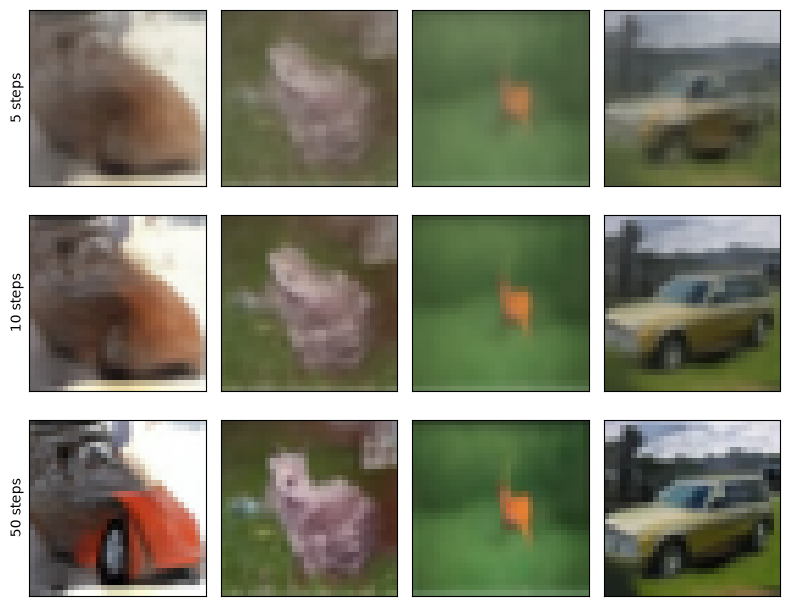

In [5]:
rows = {}
for n_steps in [5, 10, 50]:
    start = time.time()
    rows[n_steps], _, _ = generate(4, n_steps, seed=1)
    print(f'{n_steps:2} steps: {time.time() - start:.1f} s')

again, _, _ = generate(4, 50, seed=1)
print('same seed, same images:', torch.allclose(again, rows[50], atol=1e-4))

fig, axes = plt.subplots(3, 4, figsize=(8, 6.4))
for r, (n_steps, batch) in enumerate(rows.items()):
    for c in range(4):
        axes[r, c].imshow(show(batch[c])); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(f'{n_steps} steps')
plt.tight_layout()
plt.show()

The 50-step images took 7.8 seconds and the 5-step images 0.8 seconds, because the time is almost entirely the U-Net, which runs once per step. Running the 50-step version a second time with seed 1 gave the same four images. With the `DDIMScheduler` used here, the only randomness is the starting noise: the same seed always gives the same image, and a different seed gives a different one.

The 5-step images are blurred, like the guesses in Section 3 halfway through: large jumps between noise levels skip the later steps where the detail gets added. At 10 steps the same pictures are sharper, and at 50 steps sharper again (compare the car in the last column, whose windows and wheels only become clear at 50 steps). Usually the same seed leads to the same picture whatever the number of steps, as in the last three columns. The first column shows that this isn't guaranteed: with 5 and 10 steps the noise turned into a brown animal, and with 50 steps into a red car, because a different path through the noise levels made different decisions early on.

---

## Section 5: From Text to Image

The model so far makes small pictures of whatever CIFAR-10-like thing its starting noise leads to; there is no way to ask for anything in particular. Text-to-image models add two things.

- **A text encoder.** The description (the **prompt**) is turned into a list of numbers by a language model, and those numbers are given to the U-Net at every step along with the noisy image and the step number. During training the images came with captions, so the network learned to remove noise in a way that moves the image toward its caption. (Unit 23 covers how text becomes numbers.)
- **Diffusion on an autoencoder's codes.** Running 1,000 or even 25 denoising steps on a 512 × 512 color image is slow. Stable Diffusion instead uses an autoencoder like 22_2_1's, trained once on a huge number of images. Its encoder turns a 512 × 512 × 3 image into a code of 4 × 64 × 64 numbers, 48 times fewer. The diffusion runs on those codes, and at the very end the autoencoder's decoder turns the final code into pixels. This is called **latent diffusion**; "latent" is another name for a code like this one.

The model here is **BK-SDM-Small** (Nota AI, 2023), a compressed version of Stable Diffusion 1.4 with blocks removed from its U-Net, which then learned to copy the full model's outputs. It is small enough to run on Colab's free GPU. The first time it runs, the next cell downloads it (2.7 GB). **On a CPU, skip the next two cells and read their saved outputs.**

In [6]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained('nota-ai/bk-sdm-small',
                                               dtype=torch.float16 if device == 'cuda' else torch.float32).to(device)
pipe.set_progress_bar_config(disable=True)
for name in ['text_encoder', 'unet', 'vae']:
    print(f'{name:13} {sum(p.numel() for p in getattr(pipe, name).parameters()):>12,} weights')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

text_encoder   123,060,480 weights
unet           482,346,884 weights
vae             83,653,863 weights


The three parts add up to nearly 700 million weights, about 20 times the CIFAR-10 model. The U-Net has 482 million of them; the full Stable Diffusion 1.4 U-Net has about 860 million, so the compression removed nearly half. The text encoder (123 million) is part of CLIP, a model from OpenAI trained to match images with their captions. The `vae` is the autoencoder (84 million). Its name stands for **variational autoencoder**, a kind of autoencoder trained so that its codes stay in a well-behaved range; for this notebook it is enough to think of it as 22_2_1's encoder and decoder, made much larger and trained on far more images.

The next cell makes one image from a prompt, with 25 denoising steps. It also keeps the code (the **latent**) after every 5th step and runs it through the autoencoder's decoder, so we can see the image take shape, as in Section 3.

25 steps: 60 s
shape of the code (latent): (1, 4, 64, 64)


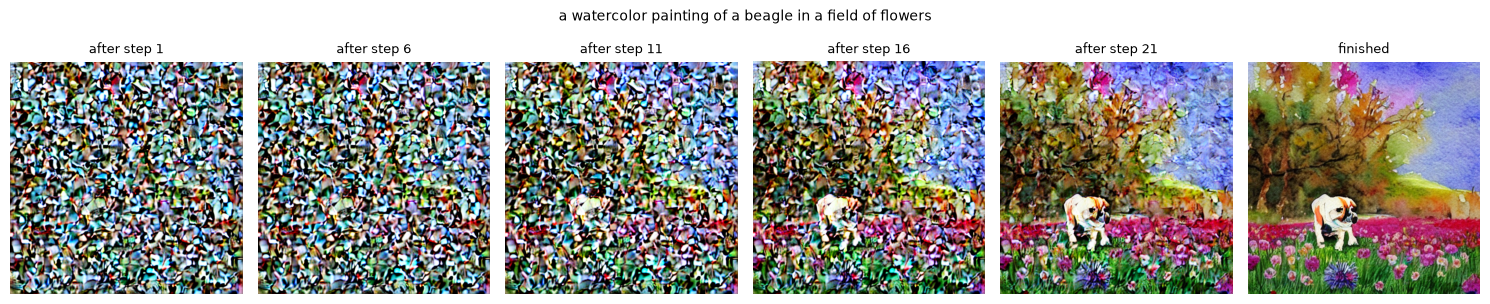

In [7]:
prompt = 'a watercolor painting of a beagle in a field of flowers'
kept = []

def keep_latent(pipeline, i, t, values):
    # Called by the pipeline after every denoising step; keeps a copy of the current code.
    if i % 5 == 0 and i < 25:
        kept.append((i, values['latents'].clone()))
    return values

start = time.time()
image = pipe(prompt, num_inference_steps=25, generator=torch.Generator().manual_seed(0),
             callback_on_step_end=keep_latent).images[0]
print(f'25 steps: {time.time() - start:.0f} s')
print('shape of the code (latent):', tuple(kept[0][1].shape))

with torch.no_grad():
    decoded = [(i, pipe.vae.decode(latent / pipe.vae.config.scaling_factor).sample[0].float())
               for i, latent in kept]

fig, axes = plt.subplots(1, len(decoded) + 1, figsize=(15, 3.2))
for ax, (i, x) in zip(axes, decoded):
    ax.imshow(show(x)); ax.set_title(f'after step {i + 1}', fontsize=9); ax.axis('off')
axes[-1].imshow(image); axes[-1].set_title('finished', fontsize=9); axes[-1].axis('off')
plt.suptitle(prompt, fontsize=10)
plt.tight_layout()
plt.show()

The code has shape (1, 4, 64, 64): one image, 4 channels of 64 × 64, for a final picture of 512 × 512 × 3. The saved output was made on a laptop CPU, where 25 steps took 60 seconds; Colab's free GPU takes a few seconds, and Colab's CPU more than 10 minutes.

Decoding the code along the way shows the same order as in Section 3. After step 1 the decoded code is a texture of coloured scraps with no picture in it. By step 11 a faint white shape has appeared where the dog will be. By step 16 the dog is clear and the layout of the scene is there (trees on the left, sky on the right, flowers along the bottom), and by step 21 the watercolor texture and the flowers are filled in.

The finished image follows most of the prompt: it looks like a watercolor painting, and the dog is standing in a field of flowers. But the dog isn't much like a beagle. It is white with brown patches on its head, and its face is closer to a bulldog's. The compressed model is less accurate than the full one, and a prompt is only a nudge on each step, not a specification. Try changing the prompt or the seed (if you have a GPU) and you'll see how much the results vary.

---

## Section 6: Where the Training Images Came From

Like 19_0_2's pet photos, everything a diffusion model can draw comes from its training images, and for text-to-image models those images raise problems of their own.

**Scraped from the web.** Stable Diffusion was trained on images and their captions collected automatically from public web pages, taken from LAION-5B, a dataset of about 5.8 billion image and text pairs released in 2022. Nobody asked the people who made the images, including artists and photographers, whether their work could be used, and a model trained on many of one artist's images can imitate that artist's style. In 2023, a group of artists and the photo agency Getty Images filed separate lawsuits against Stability AI, the company behind Stable Diffusion, over the use of their images for training.

**Memorizing training images.** A diffusion model is trained to rebuild its training images from noise, so it is fair to ask whether it ever simply reproduces one. Researchers showed in 2023 that it occasionally does: by generating a very large number of images, they found some that were near-copies of images in Stable Diffusion's training data, mostly images that appeared many times in it. Most generated images aren't copies, but the model can't tell you which ones are.

**Images of things that never happened.** A model that can draw a convincing photograph of anything a prompt describes can also draw a real person doing something they never did. Fabricated images of public figures and news events have spread widely online since these models became available. One response is to record where an image came from: camera makers and some image generators now attach signed information about how an image was made (the C2PA "content credentials" standard), although this information is easy to remove and most images don't have it.

**Filters.** The pipeline above includes a **safety checker**, a separate classifier that blanks out generated images it judges to be explicit. Like any classifier, it makes mistakes in both directions, and since the code is public, anyone running the model themselves can switch it off.

---

## Summary

- A **diffusion model** is trained to estimate the noise in an image at every level of a fixed **noise schedule** (here 1,000 steps), given the noisy image and the step number. The loss is the mean squared error between the estimated and the real noise.
- From an estimate of the noise, the formula $\text{noisy} = a_t \times \text{clean} + b_t \times \text{noise}$ gives a guess of the clean image. That guess is good when the noise is light and blurred when it is heavy, the same pattern as 22_2_1's one-step denoiser.
- To generate, start from pure noise and repeat: estimate the noise, then move to a slightly less noisy step. DDIM visits 50 of the 1,000 steps instead of all of them. The guess of the finished image starts as a blur and gains detail step by step.
- The starting noise (the seed) decides which image comes out, and the same seed gives the same image. Too few steps gives blurred images.
- **Text-to-image** models give the U-Net an encoding of the prompt at every step, and **latent diffusion** runs the denoising on the codes of an autoencoder, with the decoder turning the final code into pixels.
- The training images were scraped from the web without the creators' consent, models occasionally reproduce training images, and generated images can show events that never happened.

## What's next

That completes the image unit: from convolution by hand to a CNN, transfer learning, the ways image models fail, and models that make images. Unit 23 turns to text. Its first notebook, 23_0_1, starts with the problem the text encoder in Section 5 had to solve: before a network can do anything with a sentence, the sentence has to be turned into numbers, and the first step is splitting it into **tokens**.